# Week 3 · Ensembles: bagging, random forests, boosting

One tree is easy to read but unstable ([04 §6 ↗](04_decision_trees.ipynb)). **Ensembles combine many models into one.** **Bagging and random forests** average many deep trees to cancel out their variance. **Boosting** adds small trees one at a time, each one fixing the mistakes of the ones before. On tabular data, like most of the lab's industrial projects, gradient-boosted trees are often the model to beat. **Reading:** ISL Ch. 8.2; StatQuest on Random Forests, AdaBoost and Gradient Boost (parts 1–2).

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

## The big picture

A single tree has one of two problems. **Deep trees** have high variance, so we **average** many of them (bagging → random forest, §1–3). **Stumps** have high bias, so we **add them in sequence**, each fixing the last one's mistakes (AdaBoost → gradient boosting, §4–6).

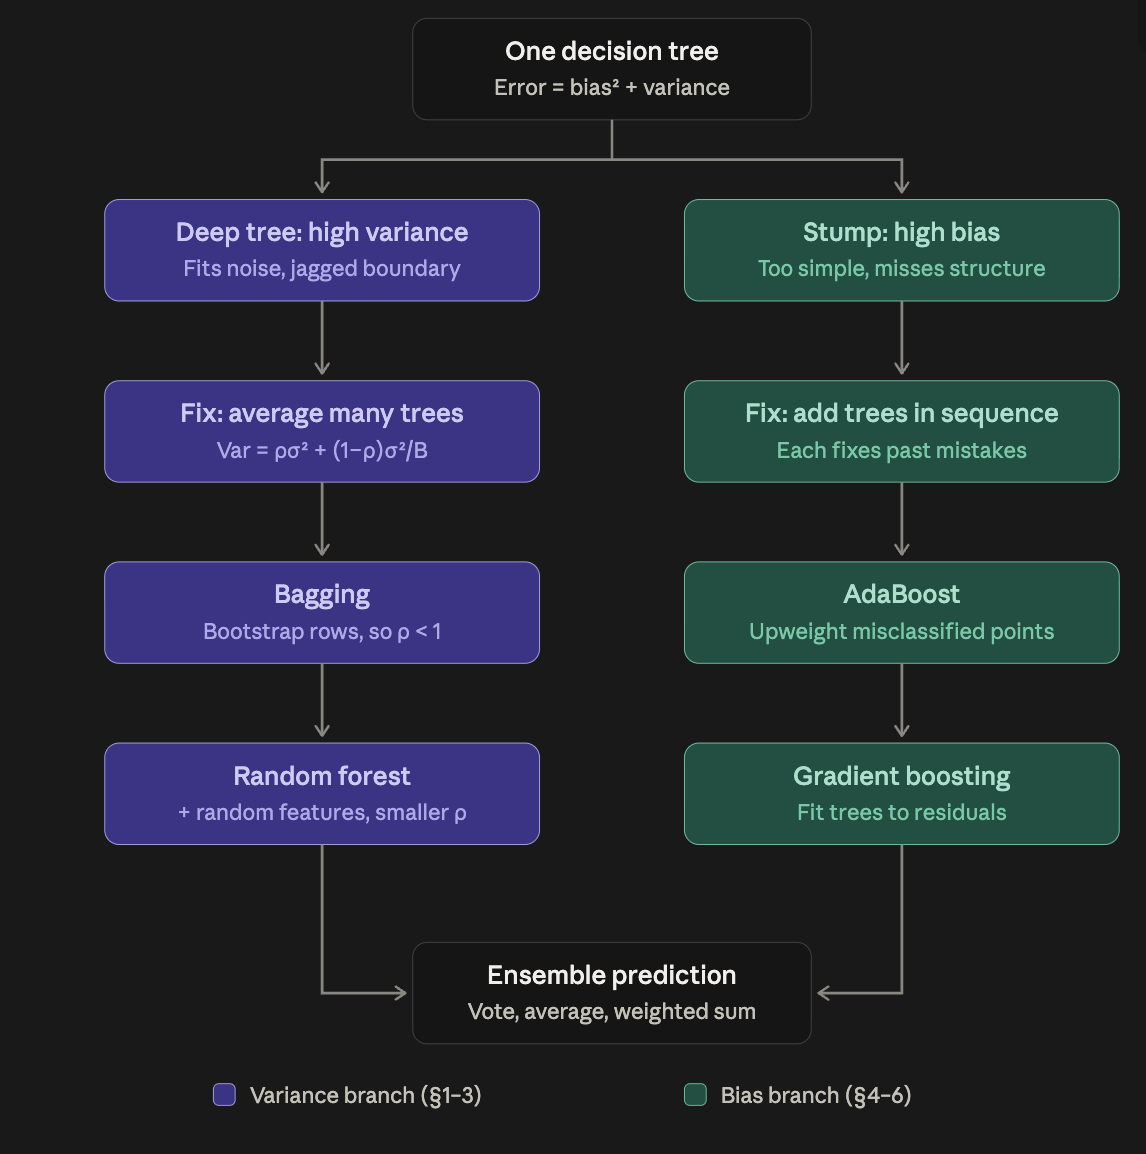

## Words you'll see
- **ensemble**: A model made of many models, whose predictions are combined by a vote or a (weighted) sum.
- **bootstrap sample**: $n$ rows drawn **with replacement** from $n$ rows: some rows appear twice or more, others not at all.
- **weak learner**: A model only slightly better than guessing, e.g. a **stump** (a tree with a single split).
- **residual**: $y_i - F(x_i)$: what the current model still gets wrong, for a numeric target.

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [68]:
import numpy as np
import matplotlib.pyplot as plt
from figures import *
import checks; checks.load(globals(), "06")      # defines check(n)

## 0. Recap first · 10 min, closed book

**Quick check:** Which training points determine an SVM's line?

<details><summary>Answer</summary>

Only the support vectors: the points on the edge of the street or inside it ($y_i z_i \le 1$). [05 §4 ↗](05_svm.ipynb)

</details>

**Quick check:** $k(x, z) = (x^\top z + 1)^2$ for $x = (1, 0)$, $z = (2, 3)$?

<details><summary>Answer</summary>

$x^\top z = 2$, so $(2 + 1)^2 = 9$. [05 §8 ↗](05_svm.ipynb)

</details>

**Quick check:** A regression tree's leaf holds the values $4, 6, 11$. What does it predict, and what is its SSE?

<details><summary>Answer</summary>

The mean, $7$. SSE $= 9 + 1 + 16 = 26$. [04 §5 ↗](04_decision_trees.ipynb)

</details>

**Quick check:** Cost-complexity pruning: a 4-leaf branch has error 0.02, and pruned to 1 leaf, 0.08. Above which $\alpha$ is it pruned?

<details><summary>Answer</summary>

Prune when $0.08 + \alpha < 0.02 + 4\alpha$, i.e. $\alpha > 0.02$. [04 §6 ↗](04_decision_trees.ipynb)

</details>

**Quick check:** `P = np.array([[0, 1, 1], [1, 1, 0], [0, 1, 0]])`. What does `np.bincount(P[:, 0]).argmax()` give, and what does it mean?

<details><summary>Answer</summary>

Column 0 is `[0, 1, 0]`, so the count is `[2, 1]` and argmax is `0`: the majority vote of three models on the first test point. [02 §5 ↗](02_knn_and_numpy_workout.ipynb)

</details>

## 1. Why averaging helps, and when it can't

**Averaging $B$ models with the same variance $\sigma^2$ shrinks the variance, but only the part that isn't shared: correlated errors don't cancel.**

**The setting.** $B$ models make predictions $X_1, \dots, X_B$ at some point. Each has variance $\sigma^2$, and every pair has correlation $\rho$, so $\text{Cov}(X_b, X_c) = \rho\sigma^2$. The ensemble predicts their average $\bar X = \frac{1}{B}\sum_b X_b$.

$$
\text{Var}(\bar X) = \rho\,\sigma^2 + \frac{1 - \rho}{B}\,\sigma^2
$$

**Where it comes from.** The variance of a sum is the sum of all variances and covariances. There are $B$ variance terms and $B(B - 1)$ covariance pairs:

$$
\text{Var}\Big(\frac{1}{B}\sum_b X_b\Big) = \frac{1}{B^2}\Big(\underbrace{B\sigma^2}_{\text{variances}} + \underbrace{B(B - 1)\rho\sigma^2}_{\text{covariances}}\Big) = \frac{\sigma^2}{B} + \frac{B - 1}{B}\rho\sigma^2 = \rho\sigma^2 + \frac{1 - \rho}{B}\sigma^2
$$

| $B$ | $\rho = 0$ | $\rho = 0.3$ | $\rho = 0.7$ |
|---|---|---|---|
| 1 | 1.000 | 1.000 | 1.000 |
| 10 | 0.100 | 0.370 | 0.730 |
| 100 | 0.010 | 0.307 | 0.703 |
| $\infty$ | 0 | 0.300 | 0.700 |

(With $\sigma^2 = 1$. For $\rho = 0.3$ and $B = 10$: $0.3 + \frac{0.7}{10} = 0.37$.)

🖼 **Picture.** More models always help, but the curve levels off at $\rho\sigma^2$. To go lower you have to make the models **less correlated**. That's the whole idea behind random forests.

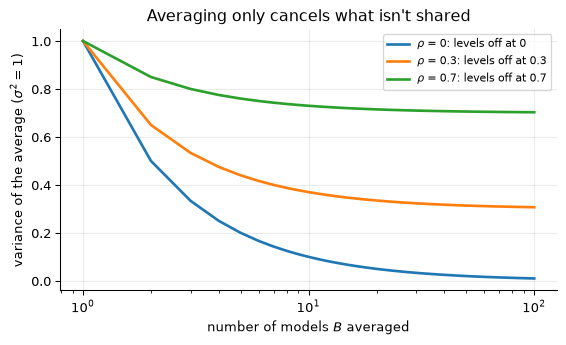

In [69]:
fig_variance_of_average()

Uses: this is why we average **deep** trees, which have low bias and high variance. Averaging keeps the low bias and removes much of the variance. Averaging stumps would keep their high bias, and averaging can't fix bias.

## 2. Bagging: bootstrap, then average

**Bagging (bootstrap aggregating) trains each model on its own bootstrap sample of the training set, then combines them by a majority vote (classification) or an average (regression).**

🖼 **Picture.** Five bootstrap samples of the same 10 training rows. Each sample draws 10 times **with replacement**: ×2 means that row was drawn twice, and *out* means it was never drawn (out-of-bag for that tree). One tree is trained on each sample, and their predictions are combined by a vote.

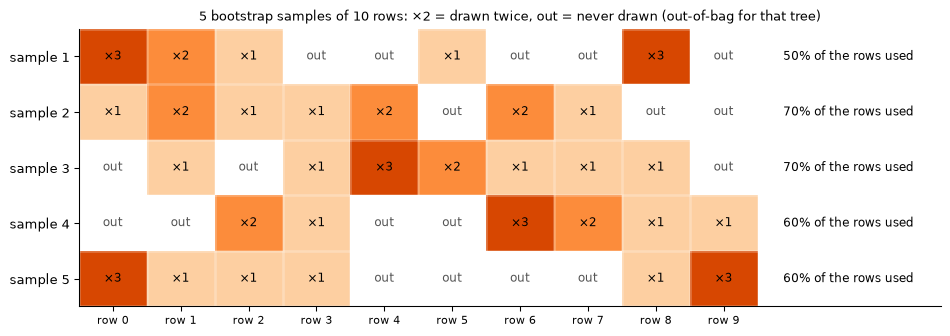

In [70]:
fig_bootstrap()

**How many distinct rows does a bootstrap sample contain?** One draw misses a given row with probability $1 - \frac{1}{n}$, so all $n$ draws miss it with probability

$$
\Big(1 - \frac{1}{n}\Big)^n \;\xrightarrow{\;n \to \infty\;}\; e^{-1} = 0.368
$$

For $n = 10$ it's $0.9^{10} = 0.349$; for $n = 1000$ it's $0.368$. So each tree sees about **63.2%** of the distinct rows, and about 36.8% are left out of it.

**Out-of-bag (OOB) error: a free validation set.** Each row is left out by about a third of the trees. Predict each row using only those trees and you get an honest error estimate without a separate validation split. In scikit-learn that's `oob_score=True`.

🖼 **Picture.** One deep tree (left) has a jagged boundary that wraps around single points. Bagging 200 trees smooths it out. A random forest (right, next section) does the same with less correlated trees.

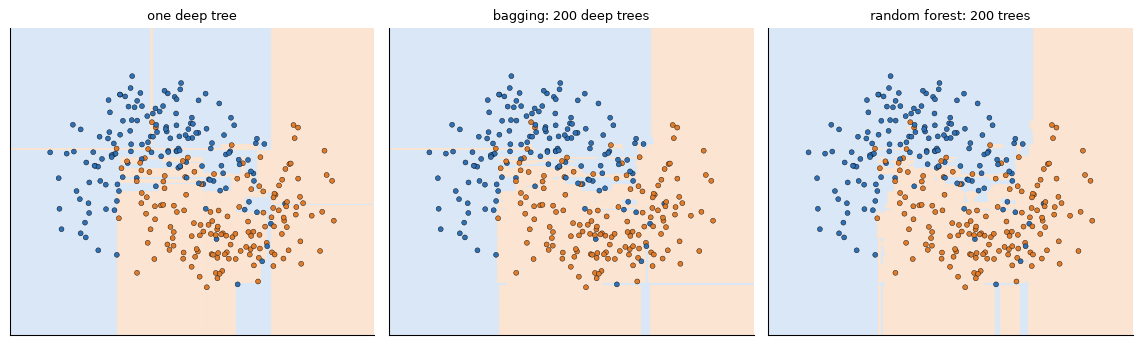

In [71]:
fig_bagging()

## 3. Random forests: decorrelate the trees

**A random forest is bagging plus one extra trick: at every split, each tree may only choose among a random subset of the features.** That makes the trees less alike (a smaller $\rho$), so averaging removes more variance.

Why does plain bagging leave the trees correlated? If one feature is very strong, almost every bootstrap tree splits on it first, so they all look alike, and from section 1, averaging look-alikes barely helps. Hiding the strong feature from some splits forces some trees to find other good structure.

| Setting (scikit-learn) | Meaning | Usual value |
|---|---|---|
| `n_estimators` | the number of trees $B$ | 100–500 (more never overfits, it just costs time) |
| `max_features` | features tried at each split, $m$ | $\sqrt{d}$ for classification (the default); $m = d$ is plain bagging |
| `max_depth`, `min_samples_leaf` | the size of each tree | usually grown deep |
| `oob_score=True` | compute the OOB accuracy |  |

**Feature importance** is the impurity decrease from [04 §7 ↗](04_decision_trees.ipynb), averaged over all trees. It's more stable than a single tree's.

In [72]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
data = load_breast_cancer()
Xa, Xt, ya, yt = train_test_split(data.data, data.target, test_size=0.25, random_state=0, stratify=data.target)
rf = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=0).fit(Xa, ya)
print(round(rf.oob_score_, 3), round(rf.score(Xt, yt), 3))     # → 0.965 0.944   OOB estimate vs real test
top = np.argsort(rf.feature_importances_)[::-1][:3]
print([str(data.feature_names[i]) for i in top])
# → ['worst perimeter', 'worst radius', 'worst concave points']

0.965 0.944
['worst perimeter', 'worst radius', 'worst concave points']


## 4. Boosting: fix the mistakes one model at a time

**Boosting builds the ensemble one small model at a time. Each new model concentrates on what the ensemble so far gets wrong, and the final prediction is a weighted sum of all of them.**

|  | Bagging / random forest | Boosting |
|---|---|---|
| models built | independently (in parallel) | one after another, each depending on the last |
| base model | deep trees (low bias, high variance) | small trees, often stumps (high bias, low variance) |
| what it reduces | variance | mainly bias |
| too many models | never hurts | eventually overfits: choose the number by CV |

## 5. AdaBoost, step by step

**AdaBoost gives every training point a weight. Each round it fits a stump to the weighted data, gives that stump a vote $\alpha$ based on its weighted error, and then raises the weights of the points it got wrong.**

**The setting.** Labels $y_i \in \{-1, +1\}$, weights $w_i$ starting at $\frac{1}{n}$, and in each round $t$ a stump $h_t(x) \in \{-1, +1\}$:

$$
\varepsilon_t = \sum_{i:\ h_t(x_i) \ne y_i} w_i \qquad \alpha_t = \frac{1}{2}\ln\frac{1 - \varepsilon_t}{\varepsilon_t} \qquad w_i \leftarrow \frac{w_i\, e^{-\alpha_t y_i h_t(x_i)}}{\text{(sum, so the weights add to 1)}}
$$

$\varepsilon_t$ is the weighted error: the total weight of the misclassified points. $\alpha_t$ is the stump's vote: it's large when $\varepsilon_t$ is small, and 0 when $\varepsilon_t = 0.5$ (a coin flip gets no say). In the update, $y_i h_t(x_i)$ is $+1$ if the point was right and $-1$ if it was wrong, so right points are multiplied by $e^{-\alpha_t}$ (down) and wrong ones by $e^{+\alpha_t}$ (up). The final model is $F(x) = \sum_t \alpha_t h_t(x)$, predicting its sign.

**Worked example (an exam classic).** 8 points on a line: $x = 1, \dots, 8$ with labels $+ + - - + + - -$. No single stump gets more than 6 right. A stump is "predict $s$ if $x > t$, otherwise $-s$"; when several stumps tie, take the leftmost.

| Round | Stump | Misclassified | $\varepsilon$ | $\alpha$ |
|---|---|---|---|---|
| 1 | $x > 2.5 \Rightarrow -1$, else $+1$ | 5, 6 | $\frac{2}{8} = 0.250$ | $\frac{1}{2}\ln 3 = 0.549$ |
| 2 | $x > 6.5 \Rightarrow -1$, else $+1$ | 3, 4 | $2 \times \frac{1}{12} = 0.167$ | $\frac{1}{2}\ln 5 = 0.805$ |
| 3 | $x > 4.5 \Rightarrow +1$, else $-1$ | 1, 2, 7, 8 | $4 \times 0.05 = 0.200$ | $\frac{1}{2}\ln 4 = 0.693$ |

**The weight update after round 1, by hand**

- Every weight starts at $\frac{1}{8} = 0.125$. $e^{-0.549} = 0.577$ and $e^{0.549} = 1.732$.
- The 6 correct points: $0.125 \times 0.577 = 0.0722$ each, $0.433$ in total. The 2 wrong points (5 and 6): $0.125 \times 1.732 = 0.2165$ each, $0.433$ in total.
- The sum is $0.866$, so after normalizing, the correct points get $\frac{0.0722}{0.866} = 0.0833 = \frac{1}{12}$ and the wrong ones get $\frac{0.2165}{0.866} = 0.25$.
- Notice that the mistakes now hold exactly **half** of the total weight. That always happens, so the same stump would score $\varepsilon = 0.5$ next round and can't simply be picked again.

🖼 **Picture.** Each row is one round. Dot size is the weight before the round, ✗ marks a mistake, and the black line is the chosen stump.

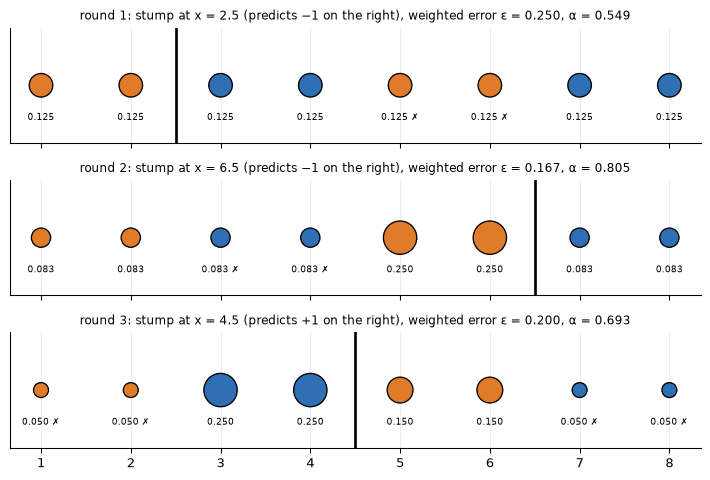

In [73]:
fig_adaboost_rounds([1, 2, 3, 4, 5, 6, 7, 8], [1, 1, -1, -1, 1, 1, -1, -1], rounds=3)

| $x$ | $h_1$ | $h_2$ | $h_3$ | $F = 0.549 h_1 + 0.805 h_2 + 0.693 h_3$ | sign | true |
|---|---|---|---|---|---|---|
| 1, 2 | +1 | +1 | −1 | +0.661 | + | + ✓ |
| 3, 4 | −1 | +1 | −1 | −0.438 | − | − ✓ |
| 5, 6 | −1 | +1 | +1 | +0.949 | + | + ✓ |
| 7, 8 | −1 | −1 | +1 | −0.661 | − | − ✓ |

Three stumps, each only 75–83% right on its own weighted data, combine into a model that gets **all 8** right. A weighted vote of weak learners can draw boundaries none of them can draw alone.

## 6. Gradient boosting: fit the residuals

**Gradient boosting starts from a constant prediction, then repeatedly fits a small tree to the current residuals and adds a fraction $\eta$ of it to the model.**

$$
F_0(x) = \bar y, \qquad r_i = y_i - F_{m-1}(x_i), \qquad F_m(x) = F_{m-1}(x) + \eta\, h_m(x), \quad h_m \text{ fitted to the } r_i
$$

**Why "gradient".** For the squared loss $L = \frac{1}{2}(y_i - F_i)^2$, the derivative with respect to the prediction is $\frac{\partial L}{\partial F_i} = -(y_i - F_i) = -r_i$. So **the residual is the negative gradient**, and adding a tree that predicts the residuals is a gradient-descent step, taken in "prediction space" instead of on weights. With other losses (log loss for classification), you fit the tree to that loss's negative gradient instead; the recipe stays the same.

**Worked example: two rounds by hand.** $x = (1, 2, 3, 4)$, $y = (1, 3, 6, 10)$, stumps, $\eta = 0.5$.

|  | $x = 1$ | $x = 2$ | $x = 3$ | $x = 4$ | MSE |
|---|---|---|---|---|---|
| $y$ | 1 | 3 | 6 | 10 |  |
| $F_0 = \bar y$ | 5 | 5 | 5 | 5 | 11.50 |
| residual $r$ | −4 | −2 | 1 | 5 |  |
| stump 1 (split at 2.5) | −3 | −3 | 3 | 3 |  |
| $F_1 = F_0 + 0.5 \times$ stump | 3.5 | 3.5 | 6.5 | 6.5 | 4.75 |
| residual $r$ | −2.5 | −0.5 | −0.5 | 3.5 |  |
| stump 2 (split at 3.5) | −1.167 | −1.167 | −1.167 | 3.5 |  |
| $F_2 = F_1 + 0.5 \times$ stump | 2.917 | 2.917 | 5.917 | 8.25 | 1.69 |

**Choosing stump 1**

- The residuals are $(-4, -2, 1, 5)$. Each candidate split predicts the mean residual on each side. Pick the one with the smallest SSE ([04 §5 ↗](04_decision_trees.ipynb)).
- Split at 1.5: $(-4)$ and $(-2, 1, 5)$ with mean 1.33, SSE $= 0 + 24.67$.
- Split at 2.5: $(-4, -2)$ with mean $-3$, SSE $= 2$; $(1, 5)$ with mean $3$, SSE $= 8$. **Total 10: the smallest.**
- Split at 3.5: $(-4, -2, 1)$ with mean $-1.67$, SSE $= 12.67$; $(5)$, SSE 0. Total 12.67.

**The learning rate $\eta$ (shrinkage).** Adding only half of each tree means more rounds are needed, but each step is cautious, which usually generalizes better. Small $\eta$ (0.05–0.1) with many rounds is standard; pick the number of rounds by CV or by early stopping.

🖼 **Picture.** Gradient boosting with stumps on a noisy sine. After 1 round it's one step; after 50 rounds, many small steps follow the curve.

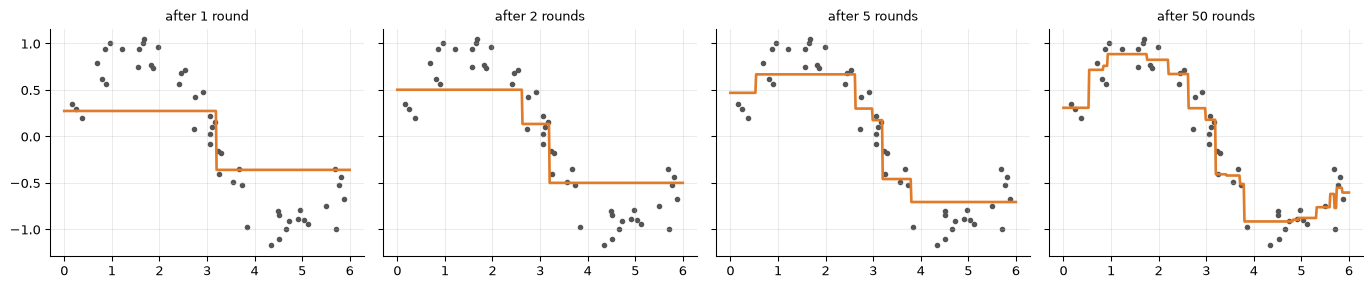

In [74]:
fig_gb_rounds(show=(1, 2, 5, 50), lr=0.5)

**XGBoost and LightGBM** are gradient boosting with engineering on top: second derivatives for better steps, an explicit penalty on tree size and leaf values, histogram-based split finding (fast on millions of rows), and native handling of missing values. Same idea, much faster. In scikit-learn, `HistGradientBoostingClassifier` is the comparable version.

## 7. All the models on the same data

🖼 **Picture.** Six classifiers (columns) on three datasets (rows). Trees and forests draw boxy shapes; kNN and RBF-SVM draw smooth blobs; logistic regression can only draw a straight line.

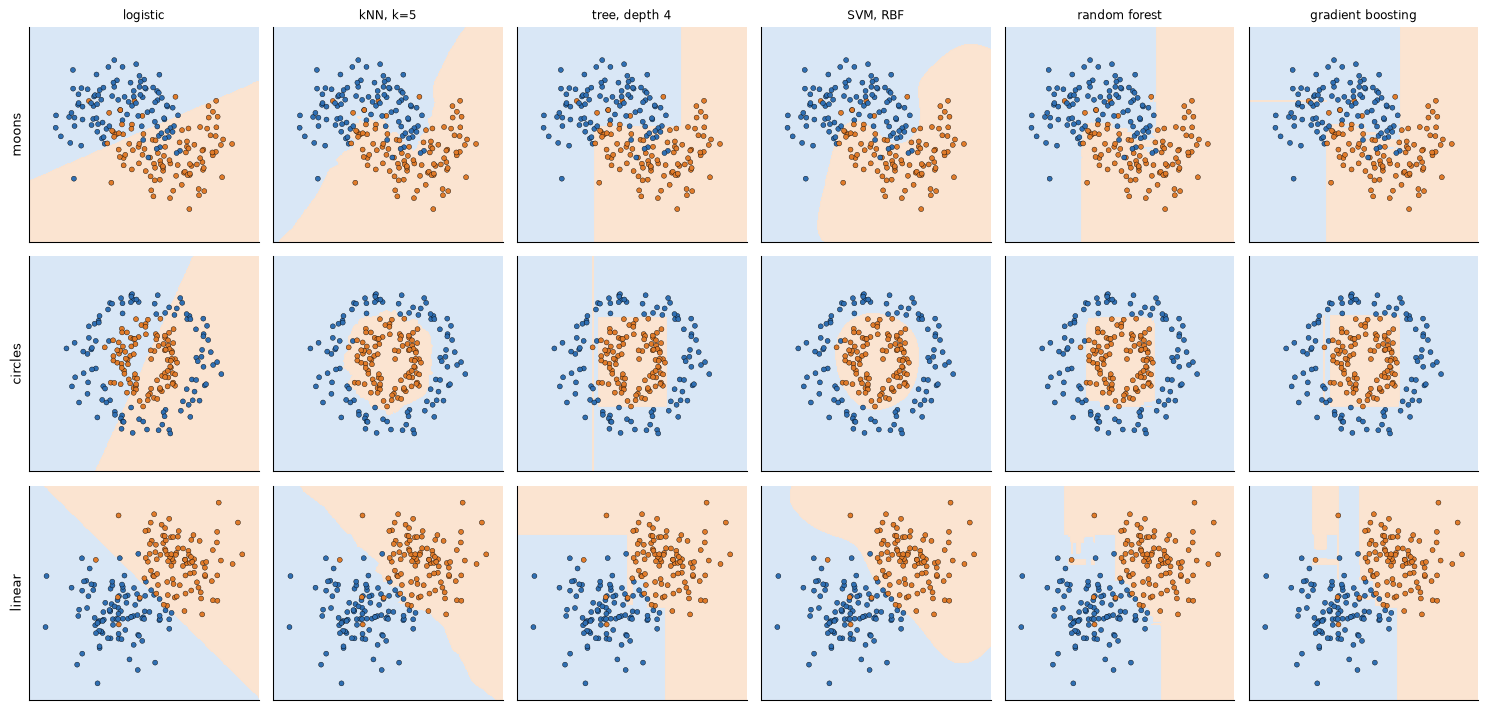

In [75]:
fig_compare_models()

In [76]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
models = {"logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          "tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=0),
          "SVM (RBF)": make_pipeline(StandardScaler(), SVC()),
          "random forest": RandomForestClassifier(n_estimators=200, random_state=0),
          "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=0),
          "gradient boosting": GradientBoostingClassifier(random_state=0)}
for name, m in models.items():
    print(f"{name:18s} CV {cross_val_score(m, Xa, ya, cv=5).mean():.3f}")
# → logistic           CV 0.974
#   tree (depth 4)     CV 0.923
#   SVM (RBF)          CV 0.986
#   random forest      CV 0.955
#   AdaBoost           CV 0.958
#   gradient boosting  CV 0.965

logistic           CV 0.974
tree (depth 4)     CV 0.923
SVM (RBF)          CV 0.986
random forest      CV 0.955
AdaBoost           CV 0.958
gradient boosting  CV 0.965


Every ensemble beats the single tree by 3–4 points, which is the variance reduction at work. On this dataset the classes are almost linearly separable, so scaled linear-ish models (logistic, SVM) are just as good. **No model wins everywhere; that's why you compare them with CV.** On messy tabular data with interactions and mixed feature types (sensor logs, production records), boosted trees usually come out on top.

## 8. Build it yourself

The base trees come from scikit-learn (`DecisionTreeClassifier`, `DecisionTreeRegressor(max_depth=1)`), so these exercises are about **the ensemble logic**. Exercises 4 and 5 use the 1-D stumps from section 5, with labels $\pm 1$.

✏️ **Exercise 1 · Bootstrap indices.** Return `n` row indices drawn with replacement, using exactly `rng.integers(0, n, size=n)` (the checker uses the same seed). **Shape `(n,)`.**

In [77]:
def bootstrap_indices(n, rng):
    return rng.integers(0 , n, size=n)

In [78]:
check(1)

Exercise 1: PASS


✏️ **Exercise 2 · Majority vote.** `P` has shape `(B, m)`: row `b` holds model `b`'s predictions (whole numbers) for `m` test points. Return the majority label for each test point, ties going to the smaller label. **Shape `(m,)`.** Vote down each **column**.

In [79]:
def majority_vote(P):
    B, m = P.shape
    l = []
    for i in range(m):
        maj = np.bincount(P[:,i]).argmax() 
        l.append(maj)
    return np.array(l)


# How does this count change for when the labels are not integers. 
# What do the labels look like for the test cases?

In [80]:
m = np.array([1,2,3,1,2,3,4,1,2,3,4,1,0]) # 1 :4, 2 :3, 3 :3, 4 :2
print(np.bincount(m))
print(np.bincount(m).argmax()) #----> maj
print(np.unique(m))
# This is just a test to understand how np.bincount & .argmax works

[1 4 3 3 2]
1
[0 1 2 3 4]


In [81]:
check(2)

Exercise 2: PASS


✏️ **Exercise 3 · Bagging.** Make `rng = np.random.default_rng(seed)`. Repeat `B` times: draw `idx = bootstrap_indices(n, rng)`, fit `DecisionTreeClassifier(random_state=0)` on `X_train[idx], y_train[idx]`, and predict `X_test`. Return `majority_vote` of the stacked predictions.

In [82]:
from sklearn.tree import DecisionTreeClassifier
def bagging_predict(X_train, y_train, X_test, B, seed):
    rng = np.random.default_rng(seed)
    l = []
    r, c = X_train.shape
    for _ in range(B):
        idx = bootstrap_indices(r,rng)
        tree = DecisionTreeClassifier(random_state = 0).fit(X_train[idx], y_train[idx])
        y_pred = tree.predict(X_test) # what does y_pred look like? --> something like (m,)?
        l.append(y_pred) # this has shape (B,m) at the end of iter but is a list
    return majority_vote(np.array(l))


In [83]:
check(3)

Exercise 3: PASS


✏️ **Exercise 4 · AdaBoost with stumps (1-D).** Return a list of `(t, s, alpha)`, one per round. Each round: find the stump (threshold `t` at a midpoint, sign `s` in `(1, -1)`, predicting `s` if `x > t` else `-s`) with the smallest **weighted** error. For ties, keep the first one found, looping over thresholds from left to right and trying `s = 1` before `s = -1`. Then compute $\alpha$ and update and normalize the weights. Clip the error into `[1e-10, 1 - 1e-10]` before the log. The checker runs the section 5 example: thresholds 2.5, 6.5, 4.5.

$$
\varepsilon_t = \sum_{i:\ h_t(x_i) \ne y_i} w_i \qquad \alpha_t = \frac{1}{2}\ln\frac{1 - \varepsilon_t}{\varepsilon_t} \qquad w_i \leftarrow \frac{w_i\, e^{-\alpha_t y_i h_t(x_i)}}{\text{(sum, so the weights add to 1)}}
$$

In [84]:
def best_stump(x, y, w):
    values = np.unique(x)
    best = (None, 1, 2.0)
    for t in (values[:-1] + values[1:]) / 2:
        for s in (1, -1):
            err = w[np.where(x > t, s, -s) != y].sum()
            if err < best[2] - 1e-12:
                best = (t, s, err)
    return best


def adaboost_fit(x, y, rounds):
    w = np.full(len(x), 1 / len(x))
    model = []
    for _ in range(rounds):
        t, s, err = best_stump(x, y, w)
        err = min(max(err, 1e-10), 1 - 1e-10)         
        alpha = 0.5 * np.log((1 - err) / err)
        h = np.where(x > t, s, -s)
        w = w * np.exp(-alpha * y * h)
        w = w / w.sum()
        model.append((t, s, alpha))
    return model

In [85]:
check(4)

Exercise 4: PASS


✏️ **Exercise 5 · AdaBoost prediction.** $F(x) = \sum_t \alpha_t h_t(x)$; return `+1` where $F \ge 0$ and `-1` elsewhere. **Shape `(len(x),)`.**

In [86]:
def adaboost_predict(model, x): # model --> (t, s, alpha) s being sign
    F = sum(alpha * np.where(x>t, s, -s) for t, s, alpha in model)# want to define F(x) first
    return np.where(F >= 0, 1, -1)

In [87]:
check(5)

Exercise 5: PASS


✏️ **Exercise 6 · Gradient boosting for regression.** `gb_fit`: start from `f0 = y.mean()`; each round, fit `DecisionTreeRegressor(max_depth=1, random_state=0)` to the residuals `y - F` (with `x[:, None]` as the 2-D input), and update `F += lr * tree.predict(...)`. Return `(f0, trees)`. `gb_predict`: $f_0 + \eta \sum_m h_m(x)$.

In [88]:
from sklearn.tree import DecisionTreeRegressor

def gb_fit(x, y, rounds, lr):
    f0 = y.mean()
    F = np.full(len(y), f0)
    trees = []
    for _ in range(rounds):
        tree = DecisionTreeRegressor(max_depth=1, random_state=0).fit(x[:, None], y - F)
        F = F + lr * tree.predict(x[:, None])
        trees.append(tree)
    return f0, trees


def gb_predict(f0, trees, lr, x):
    return f0 + lr * sum(t.predict(x[:, None]) for t in trees)

In [89]:
check(6)

Exercise 6: PASS


In [90]:
for n in range(1, 7):
    check(n)

Exercise 1: PASS
Exercise 2: PASS
Exercise 3: PASS
Exercise 4: PASS
Exercise 5: PASS
Exercise 6: PASS


---
Solutions: `solutions/06_solutions.py`. Next: `07_paper_practice.ipynb`, exam-style problems by hand.